   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

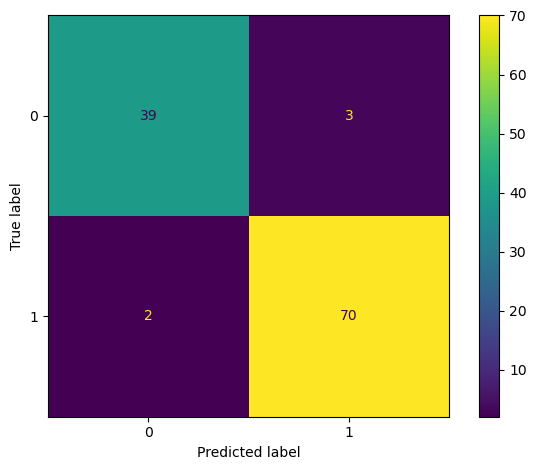

Saved model to random_forest.joblib


In [2]:
#1. Random Forest
!pip install scikit-learn pandas matplotlib joblib
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
 ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
from sklearn.base import clone

data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X = df.drop(columns="target")
y = df["target"]

print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y
)
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state=42)
steps = [("model", model)]
pipe = Pipeline(steps)

search = GridSearchCV(pipe, {"model__n_estimators": [50, 100], "model__max_depth": [None, 8]}, cv=3, scoring="f1_weighted", n_jobs=-1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1:", f1_score(y_test, pred, average="weighted", zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.tight_layout()
plt.show()

joblib.dump(best_model, "random_forest.joblib")
print("Saved model to random_forest.joblib")

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

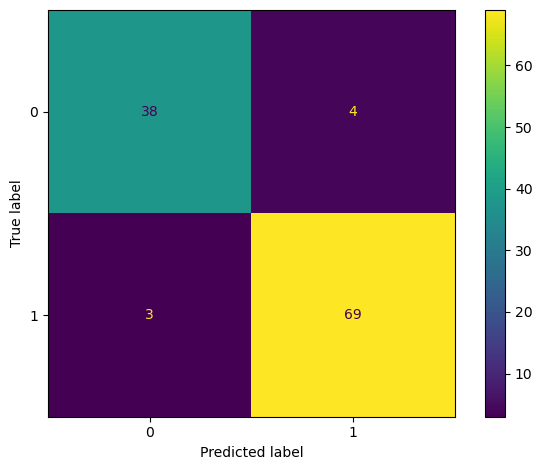

Saved model to bagging_classifier.joblib


In [4]:
#2 Bagging Classifier
!pip install scikit-learn pandas matplotlib joblib
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
 ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
from sklearn.base import clone

data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X = df.drop(columns="target")
y = df["target"]

print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y
)
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
model = BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=42)
steps = [("model", model)]
pipe = Pipeline(steps)

search = GridSearchCV(pipe, {"model__n_estimators": [10, 30], "model__max_samples": [0.7, 1.0]}, cv=3, scoring="f1_weighted", n_jobs=-1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1:", f1_score(y_test, pred, average="weighted", zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.tight_layout()
plt.show()

joblib.dump(best_model, "bagging_classifier.joblib")
print("Saved model to bagging_classifier.joblib")